<a href="https://colab.research.google.com/github/Gunakemm/Jupyter/blob/main/123/alpha_task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.graph_objects as go

In [ ]:
orig_df = pd.read_excel('Training.xlsx')

In [ ]:
df = orig_df.copy()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 91528 entries, 0 to 91527
Data columns (total 28 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ID      91528 non-null  int64  
 1   A       86943 non-null  float64
 2   B       91528 non-null  float64
 3   C       91528 non-null  float64
 4   D       91528 non-null  float64
 5   E       88800 non-null  float64
 6   F       91528 non-null  float64
 7   G       91528 non-null  int64  
 8   H       77807 non-null  float64
 9   I       91528 non-null  object 
 10  J       91528 non-null  float64
 11  K       87697 non-null  object 
 12  L       83281 non-null  float64
 13  M       91528 non-null  object 
 14  N       91528 non-null  object 
 15  O       91528 non-null  object 
 16  P       91528 non-null  object 
 17  Q       91528 non-null  object 
 18  R       91528 non-null  object 
 19  S       87854 non-null  object 
 20  T       91528 non-null  object 
 21  U       91071 non-null  object 
 22

In [ ]:
df = df.drop_duplicates(subset=['ID'])
df = df.drop(columns=['ID'])

In [ ]:
obj_cols = df.select_dtypes(include=['object']).columns
df[obj_cols] = df[obj_cols].apply(lambda x: x.str.lower().str.strip())

categorical_features = ['G', 'H']
for feat in categorical_features:
    nan_mask = df[feat].isna()
    df[feat] = df[feat].astype(str)
    df.loc[nan_mask, feat] = np.nan

bool_features = ['R', 'T', 'U', 'V', 'W', 'X']
for feature in bool_features:
    df[feature] = df[feature].map({'yes':True, 'no':False})

In [ ]:
features = df.columns.drop(['ID', 'MARKER'])

features_df = df[features].copy()
features_df.describe()

In [ ]:
df[df['MARKER'] == 1].describe()

In [ ]:
df[df['MARKER'] == 0].describe()

**Признак D**. Кредитная сумма

**Признак H**. Какой-то процент или ставка.

**Признак I**. Пол человека.

**Признка J** Возраст человека.

**Признак K**. Регион.

**Признак L**. Стаж на текущем месте работы

**Признак M**. ? Как-то связано с занимаемой должностью

**Признак N**. Образование.

**Признак O**. Семейное положение.

**Признак P**. Количество детей.

**Признак Q**. Форма владения жильем.

**Признак S**. Рабочее положение.

**Признак Y**. Какая-то оценка клиента

In [ ]:
def plot_categorical_grid(df: pd.DataFrame, hue_col: str, ncols: int=4, figsize_per: tuple=(4, 5)):

    x_cols = df.select_dtypes(include=['object']).columns.to_list()

    melted = df[x_cols + [hue_col]].melt(
        id_vars=[hue_col], var_name='feature', value_name='category'
    )

    pct_df = (
        melted.groupby(['feature', 'category', hue_col])
                .size()
                .reset_index(name='count')
    )

    pct_df['pct'] = (
        pct_df.groupby(['feature', hue_col])['count']
                .transform(lambda x: x / x.sum() * 100)
    )

    g = sns.catplot(
        data=pct_df,
        x='category',
        y='pct',
        col='feature',
        hue=hue_col,
        kind='bar',
        col_wrap=ncols,
        height=figsize_per[1],
        aspect=figsize_per[0] / figsize_per[1],
        sharex=False,
        sharey=True,
        legend_out=True,
        estimator='sum',
        errorbar=None
    )

    for ax in g.axes.flat:
        title = ax.get_title()
        ax.set_title(title.replace("feature = ", "").replace("_", " ").title(),
                     fontsize=11, pad=10)
        ax.set_ylabel('%', fontsize=10)
        ax.set_xlabel('')
        ax.tick_params(axis='x', rotation=45, labelsize=8)
        ax.spines[['top', 'right']].set_visible(False)

        # Добавляем метки процентов на бары
        for container in ax.containers:
            ax.bar_label(container, fmt='%.0f%%', fontsize=7, padding=2)

    g.add_legend(title=hue_col.title())
    plt.tight_layout(pad=2.0)
    return g

plot_categorical_grid(df=df, hue_col='MARKER')
plt.show()

In [ ]:
d = {'single/unmarried':'single', 'divorced/widow':'single', 'cohabitation':'married', 'married': 'married'}
marital_df = df[['O', 'MARKER']].copy()
marital_df['O'] = marital_df['O'].map(d)

marital_status = marital_df.groupby('MARKER', as_index=False).value_counts(normalize=True)
marital_status['proportion'] *= 100
g = sns.catplot(
    marital_status,
    x='O', y='proportion', hue='MARKER',kind='bar', sharey=True, legend_out=True, sharex=False,
)
for ax in g.axes.flat:
    ax.set_ylabel('%', fontsize=10)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.0f%%', fontsize=7, padding=2)

In [ ]:
mask = (df['M'] == 'ne employee') & (df['N'] == 'secondary education (plus special education)')
print(round(len(df[mask & df['MARKER'] == 1]) / (df['MARKER'] == 1).sum() * 100, 2))

In [ ]:
test_df = df[['J', 'MARKER']].copy()
test_df['age_bar'] = test_df['J'] // 10
test_df = test_df.drop(columns=['J'])

age_value_counts = test_df.groupby('MARKER', as_index=False).value_counts(normalize=True)
age_value_counts['proportion'] *= 100
g = sns.catplot(
    age_value_counts,
    x='age_bar', y='proportion', hue='MARKER',kind='bar', sharey=True, legend_out=True, sharex=False,
)
for ax in g.axes.flat:
    ax.set_ylabel('%', fontsize=10)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.0f%%', fontsize=7, padding=2)

Большенство клиентов с целевым признаком равным 1 - это люди в возрасте до 40 лет (64%)

In [ ]:
import plotly.express as px

period = 12
data = df['L'] // period

fig = px.histogram(x=data, title=f'Гистограмма распределения колонки "L" с шириной бина {period}', height=600)
fig.show()

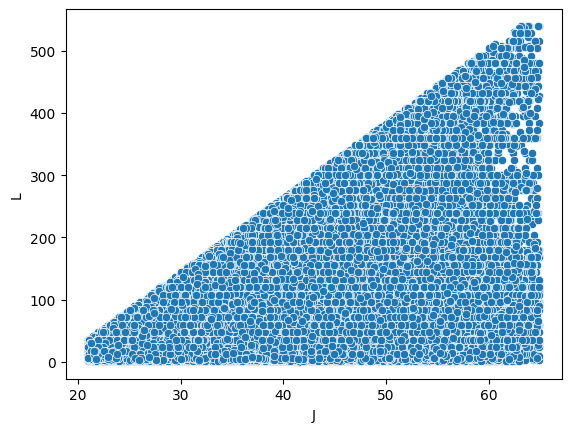

In [ ]:
sns.scatterplot(data=df, x='J', y='L', )
plt.show()

In [ ]:
mask = df['L'] <= 10
data = df[mask]

px.histogram(data_frame=data, x='L', title='Гистограмм распределения параметра "L" при "L" <= 10', height=600)

Скорее всего, столбец "L" отвечает за трудовой стаж на текущем месте работы. Однако, это не совсем стыкуется с требованиями к кредитополучателю, где указано, что трудовой стаж на текущем рабочем месте должен быть не менее 3 месяцев. Возможно, что данная информация может обновляться и если клиент ранее, при получении карты, соответствовал требованиям, то после смены работы и обнавления информации о клиенте и получаются значения меньше 3.

Пропуски в столбце "L" можно заполнить средним значение "L" для указанного возраста (можно использовать не точное совпадение возраста, а использовать значение полных лет)

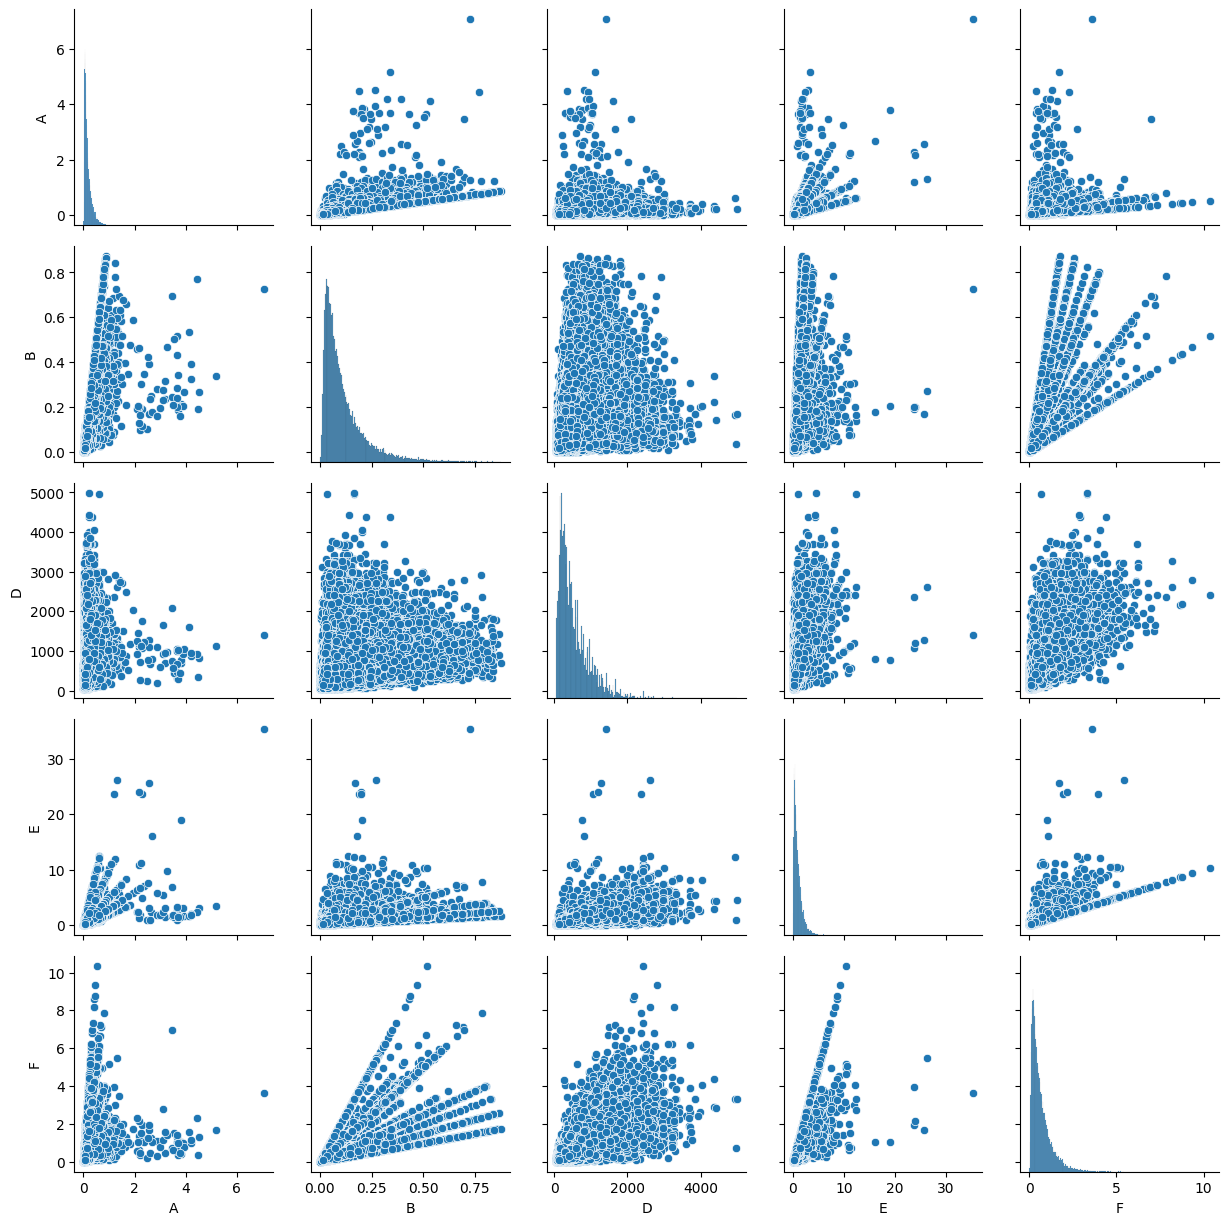

In [ ]:
g = sns.PairGrid(df[['A', 'B', 'D', 'E', 'F']])
g.map_diag(sns.histplot)
g.map_offdiag(sns.scatterplot)

<Axes: xlabel='A/B', ylabel='E/F'>

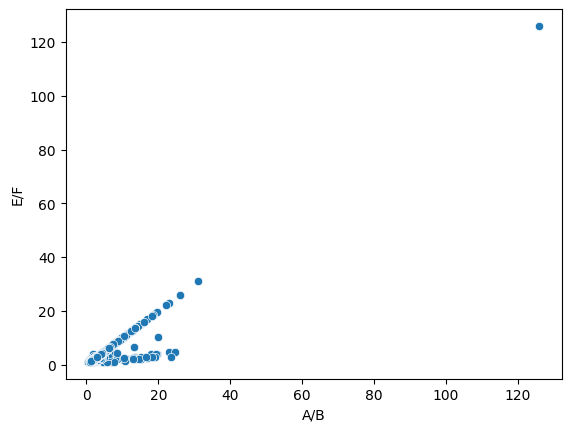

In [ ]:
data1 = df['A'] / df['B']
data2 = df['E'] / df['F']
data = df[['A', 'B', 'E', 'F']].copy()
data['A/B'] = data['A'] / data['B']
data['E/F'] = data['E'] / data['F']

data['is_close'] = abs(data['A/B'] - data['E/F']) < 1e-4
sns.scatterplot(data, x='A/B', y='E/F')

In [ ]:
wrong_proportions_mask = (data['is_close'] == False) & (pd.notna(data['A/B'])) & (pd.notna(data['E/F']))
total_not_close = (data['is_close'] == False).sum()
wrong_proportions = wrong_proportions_mask.sum()
proportion_misses = total_not_close - wrong_proportions
print(f'Всего строк с несовпадением пропорций "A/B" и "E/F": {total_not_close}. Из них пропуски в столбце "A" или "E": {proportion_misses}, и неравенства пропорций: {wrong_proportions}' )
print(f"В процентках от общего количества данных:")
print(f'Несовпадением пропорций "A/B" и "E/F": {round(total_not_close / len(df) * 100, 2)}%')
print(f'Пропуски в столбце "A" или "E": {round(proportion_misses / len(df) * 100, 2)}%')
print(f'Неравенства пропорций": {round(wrong_proportions / len(df) * 100, 2)}%')

Всего строк с несовпадением пропорций "A/B" и "E/F": 7598. Из них пропуски в столбце "A" или "E": 7184, и неравенства пропорций: 414
В процентках от общего количества данных:
Несовпадением пропорций "A/B" и "E/F": 8.3%
Пропуски в столбце "A" или "E": 7.85%
Неравенства пропорций": 0.45%


Таким образом получается, что отношение $\frac{A}{B} = \frac{E}{F}$ справедливо и можно заполнить пропуски в данных исходя из этой пропорции.

Оставшиеся пропуски можно либо дропнуть, либо заполнить следующим образом A = B, E = F

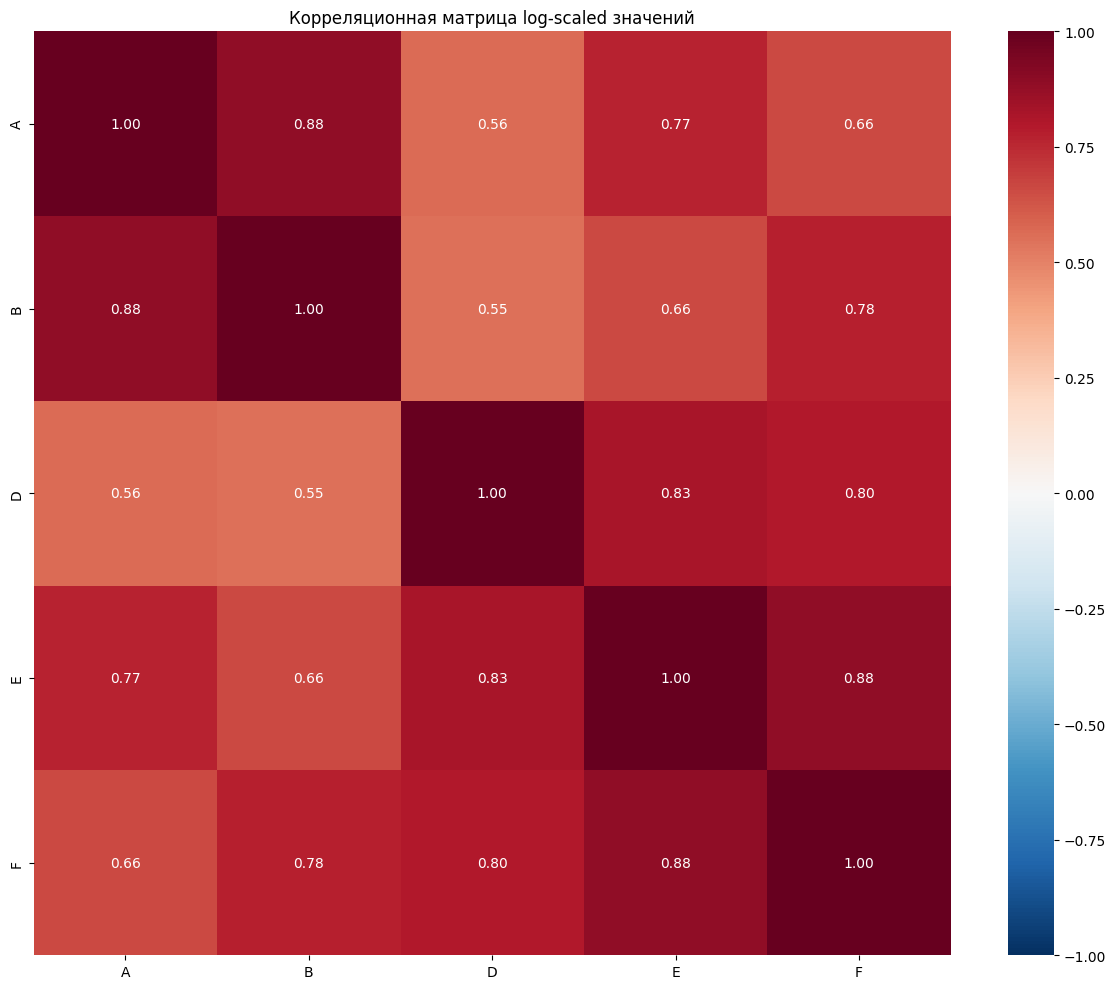

In [ ]:
cols = ['A', 'B', 'D', 'E', 'F']
test_df = df[cols].copy().dropna()
df_log = np.log(test_df.clip(lower=1e-9))

corr_matrix = df_log.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1, vmax=1
)
plt.title('Корреляционная матрица log-scaled значений')
plt.tight_layout()
plt.show()

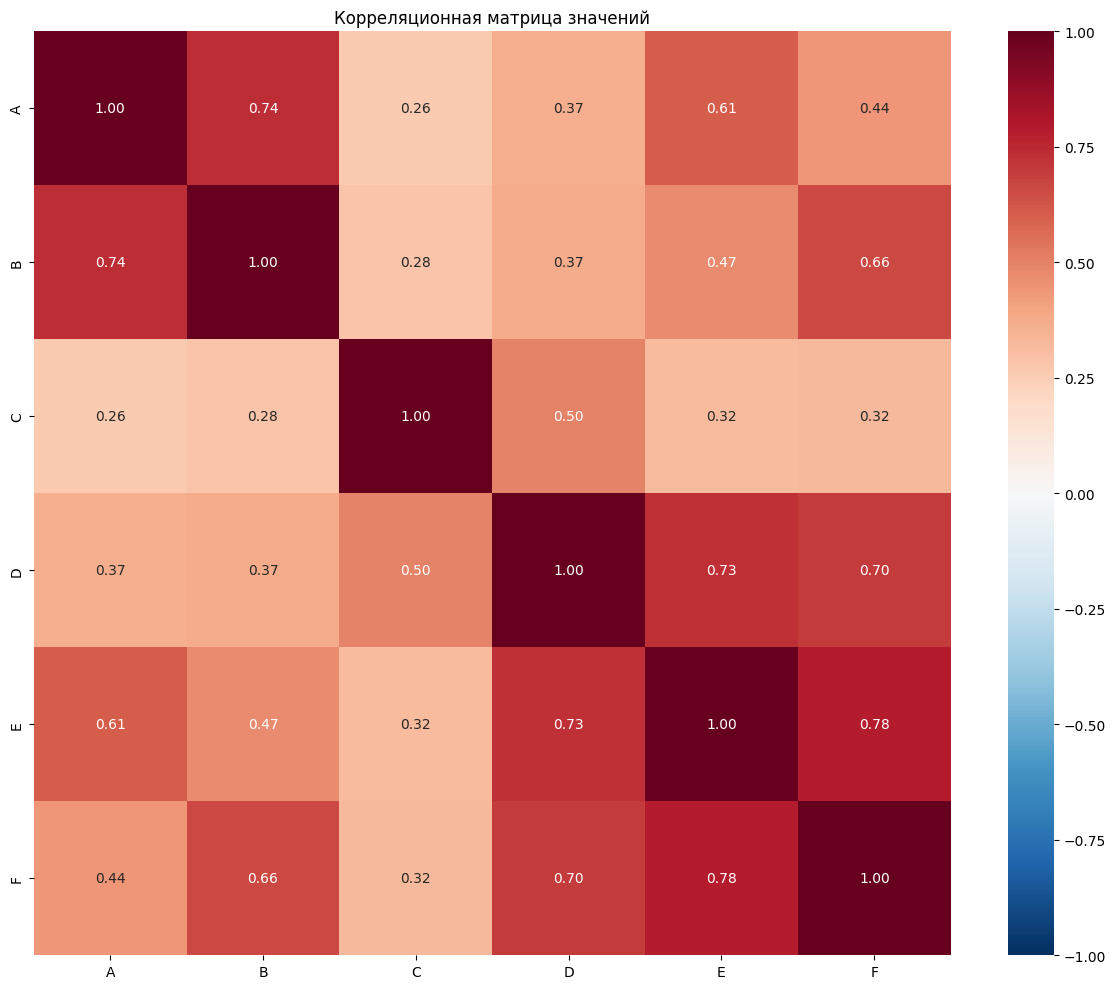

In [ ]:
corr_matrix = df[['A', 'B', 'C', 'D', 'E', 'F']].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1, vmax=1
)
plt.title('Корреляционная матрица значений')
plt.tight_layout()
plt.show()

In [ ]:
ser = df['C'] / df['D'] * 100
ser.describe()

count    91528.000000
mean        18.108888
std         15.614272
min          0.000000
25%          5.264170
50%         11.120447
75%         25.011031
max         64.027149
dtype: float64

In [ ]:
df.groupby(['G'])['H'].describe()

,count,mean,std,min,25%,50%,75%,max
G,,,,,,,,
2,4634.0,0.000000,0.000000e+00,0.00,0.00,0.000,0.000,0.00
3,12822.0,0.000000,0.000000e+00,0.00,0.00,0.000,0.000,0.00
4,3127.0,0.000000,0.000000e+00,0.00,0.00,0.000,0.000,0.00
5,21555.0,0.000000,0.000000e+00,0.00,0.00,0.000,0.000,0.00
6,1312.0,0.000000,0.000000e+00,0.00,0.00,0.000,0.000,0.00
9,450.0,1.197622,6.666834e-02,1.10,1.17,1.235,1.235,1.32
10,10915.0,0.000000,0.000000e+00,0.00,0.00,0.000,0.000,0.00
11,697.0,0.000000,0.000000e+00,0.00,0.00,0.000,0.000,0.00
13,18975.0,2.034477,6.056658e-01,0.01,1.99,1.990,2.490,3.50


/tmp/ipykernel_5644/2967221415.py:20: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_5644/2967221415.py:20: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_5644/2967221415.py:20: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_5644/2967221415.py:20: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_5644/2967221415.py:20: FutureWarning:



Passing `palette` without assigning `hue` is depreca

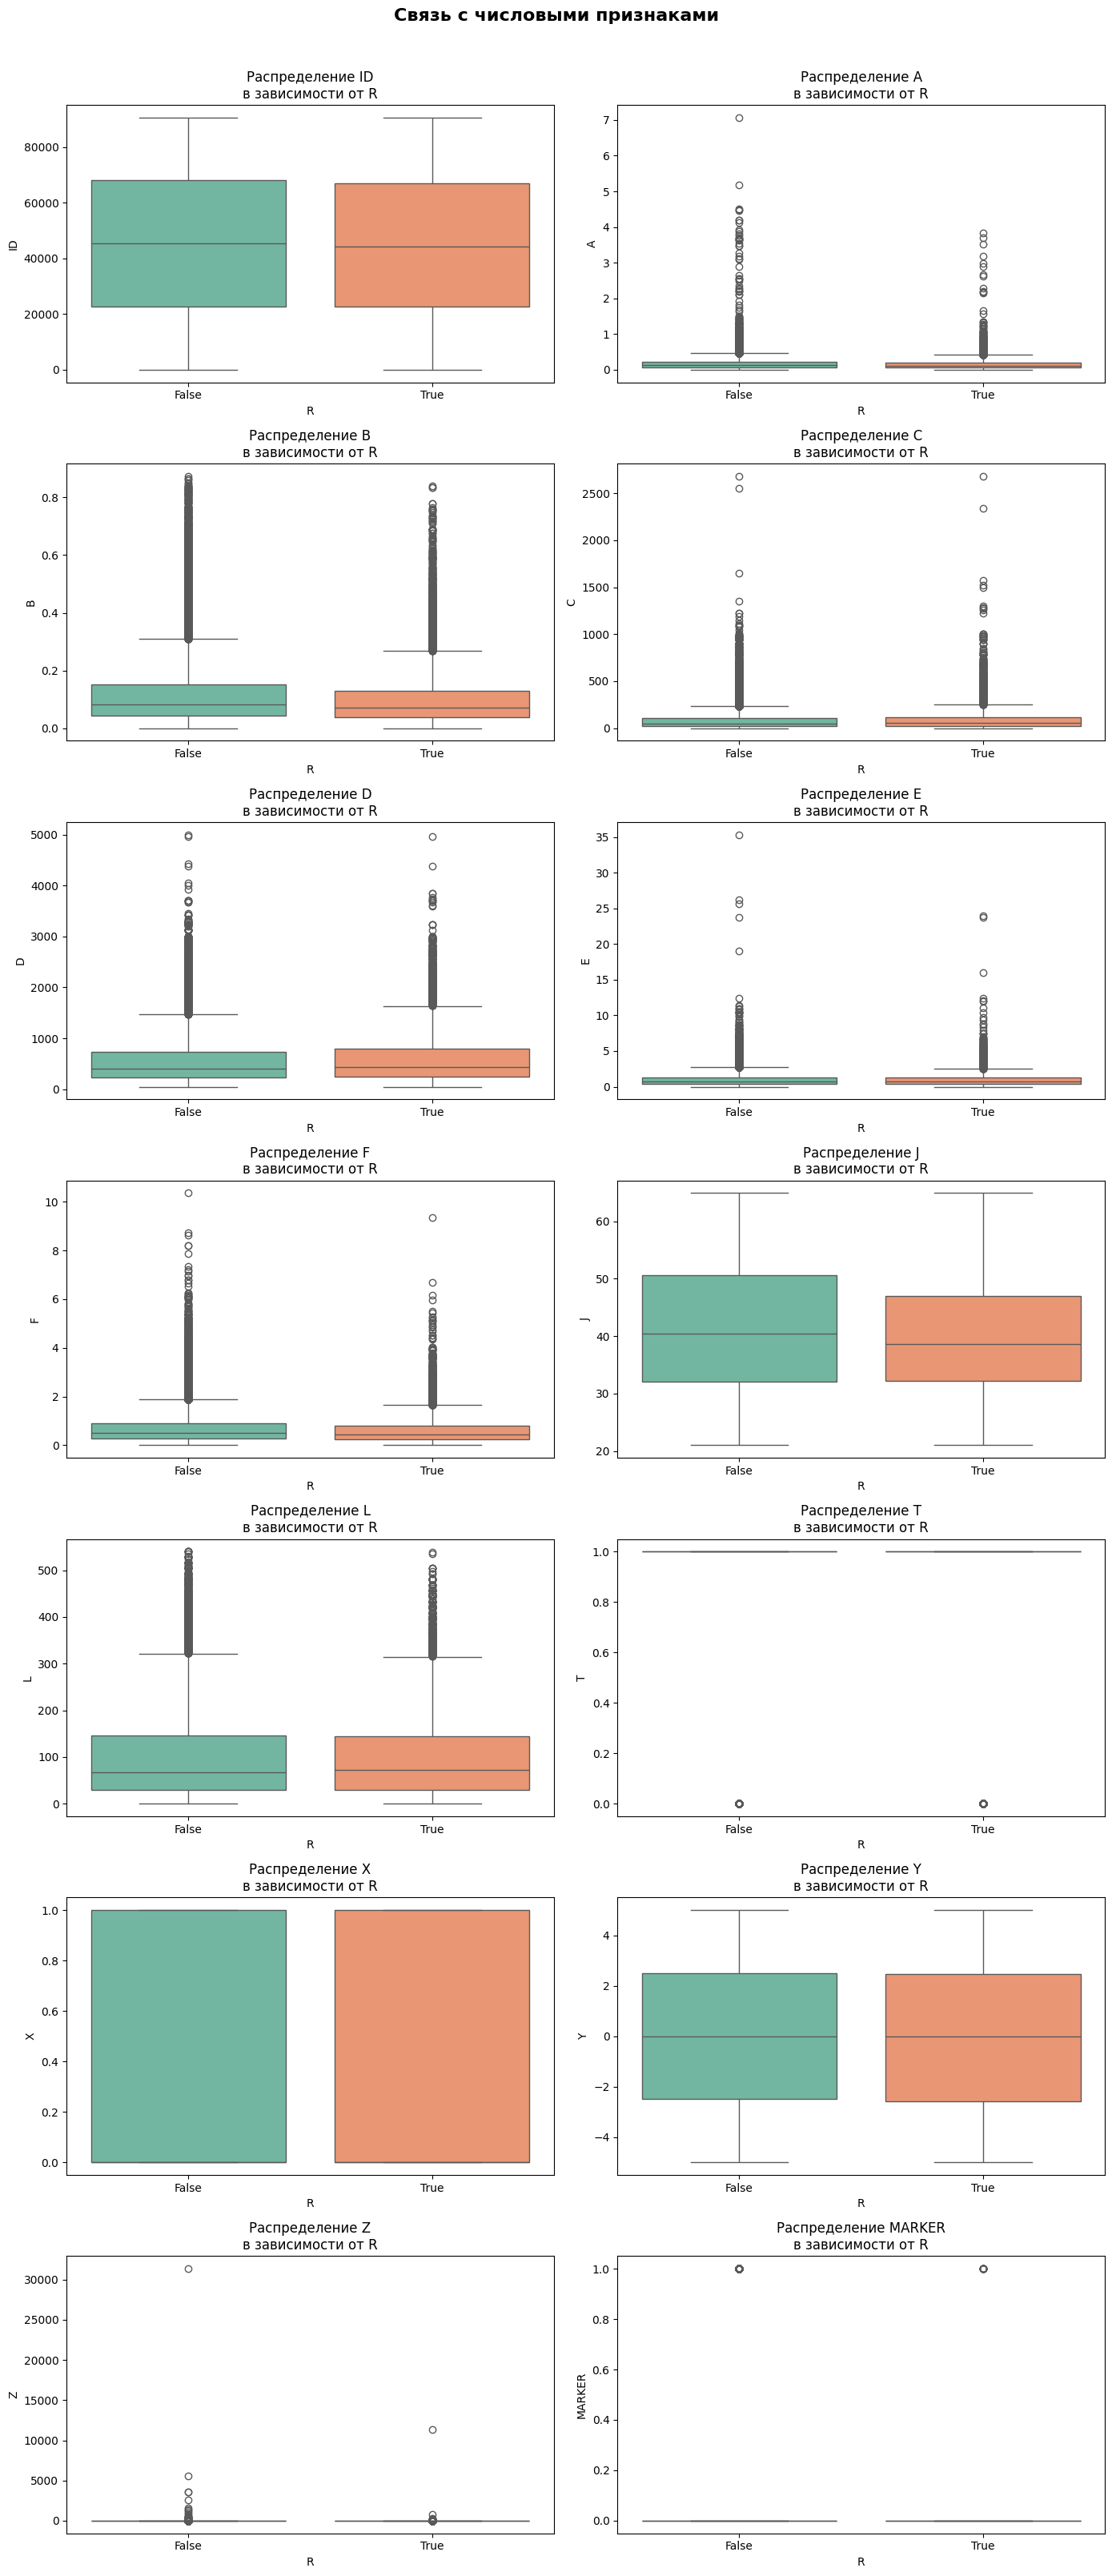

In [ ]:
bool_column = 'R'

features = [col for col in df.columns if col != bool_column]
num_features = [
    col for col in features if pd.api.types.is_numeric_dtype(df[col])
]
cat_features = [
    col for col in features if not pd.api.types.is_numeric_dtype(df[col])
]

if num_features:
    n_num = len(num_features)
    cols = 2
    rows = int(np.ceil(n_num / cols))

    fig, axes = plt.subplots(rows, cols, figsize=(14, rows * 4.5))
    axes = axes.flatten()

    for i, col in enumerate(num_features):
        sns.boxplot(ax=axes[i], data=df, x=bool_column, y=col, palette='Set2')
        axes[i].set_title(f'Распределение {col}\nв зависимости от {bool_column}')
        axes[i].set_xlabel(bool_column)
        axes[i].set_ylabel(col)

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.suptitle('Связь с числовыми признаками', y=1.02, fontsize=16, weight='bold')
    plt.show()

In [ ]:
import phik

phik_matrix = df.phik_matrix()
print("Коэффициент связи Phik с другими фичами:")
print(phik_matrix['R'].sort_values(ascending=False))

interval columns not set, guessing: ['A', 'B', 'C', 'D', 'E', 'F', 'J', 'L', 'Y', 'Z', 'MARKER']
Коэффициент связи Phik с другими фичами:
R         1.000000
K         0.247318
I         0.246942
O         0.199898
W         0.194777
U         0.125467
J         0.124701
S         0.121922
M         0.097827
V         0.089878
P         0.089466
B         0.068498
N         0.068012
D         0.062355
F         0.053586
H         0.051240
L         0.042955
T         0.033091
Q         0.031958
G         0.031161
MARKER    0.027696
C         0.019907
Z         0.011653
E         0.010581
Y         0.008671
A         0.003284
X         0.000000
Name: R, dtype: float64


<Axes: >

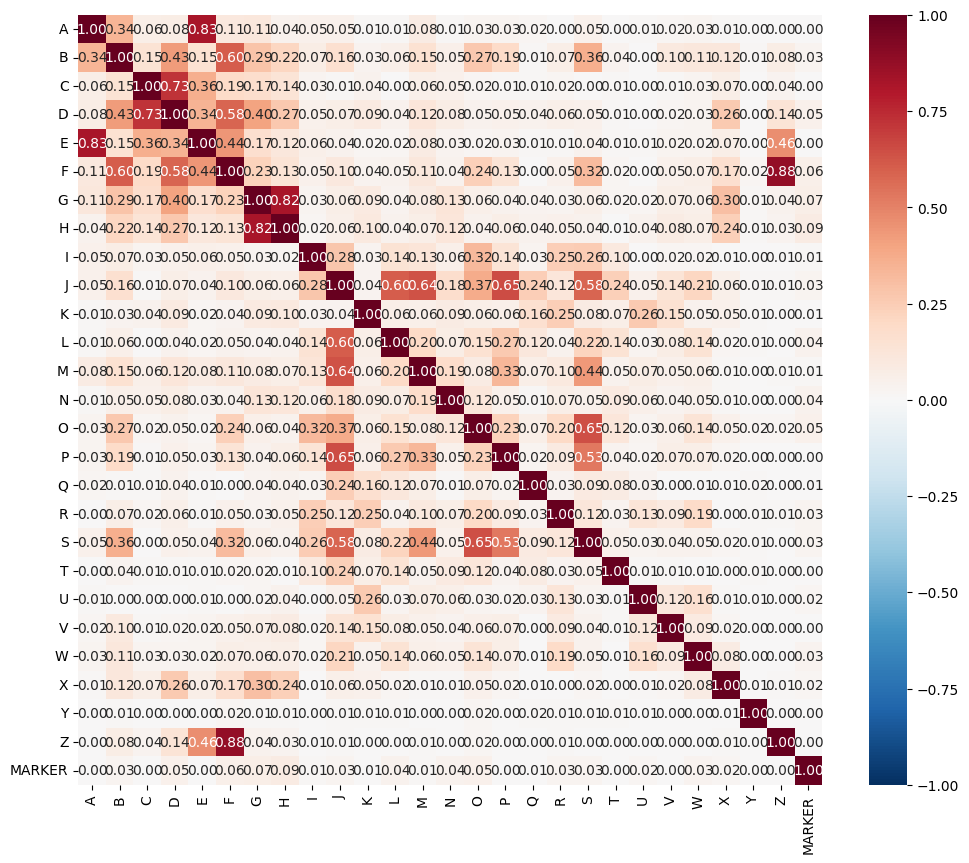

In [ ]:
plt.figure(figsize=(12, 10))
sns.heatmap(
    phik_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1, vmax=1
)

<Axes: xlabel='F', ylabel='log_z'>

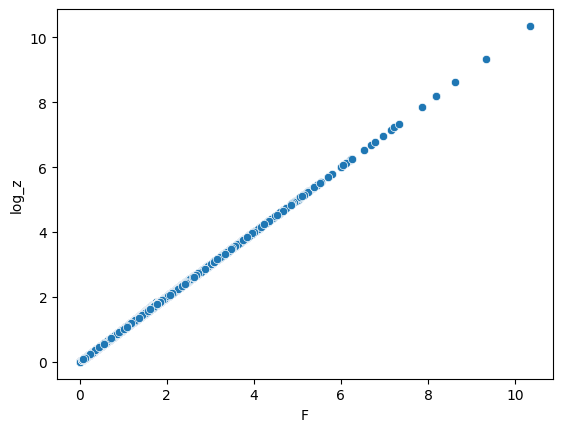

In [ ]:
test_df = df[['F', 'Z']].copy()
test_df['F/Z'] = test_df['F'] / test_df['Z']
test_df['log_z'] = np.log(test_df['Z'])
# test_df = test_df[test_df['F'] <= test_df['F'].quantile(0.99)]

sns.scatterplot(test_df, x='F', y='log_z')

In [ ]:
mask = df['F'] < df['F'].quantile(0.99)
df = df[mask]